In [1]:
import os
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
import torch.optim as optim
from torchvision.utils import make_grid
from torchvision import transforms
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from PIL import Image
import matplotlib.pyplot as plt
import timeit
from tqdm import tqdm
import seaborn as sns
import altair as alt
import random
from torch.cuda.amp import GradScaler, autocast
from transformers import AutoImageProcessor, AutoModel


import warnings
warnings.filterwarnings("ignore")

os.environ['CUDA_LAUNCH_BLOCKING'] = '1'
os.environ['TORCH_USE_CUDA_DSA'] = '1'

In [2]:
class CustomImageDataset(Dataset):
    def __init__(self, root_dir, dataset_type, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.images = []
        self.labels = []

        for sub_dataset in os.listdir(root_dir):
            sub_dataset_path = os.path.join(root_dir, sub_dataset)
            for nasted_dir in os.listdir(sub_dataset_path):
                nasted_dir_path = os.path.join(sub_dataset_path, nasted_dir)
                dataset_type_dir = os.path.join(nasted_dir_path, dataset_type)
                for label in os.listdir(dataset_type_dir):
                    label_folder = os.path.join(dataset_type_dir, label)
                    for image_name in os.listdir(label_folder):
                        image_path = os.path.join(label_folder, image_name)
                        self.images.append(image_path)
                        self.labels.append(label)

        self.label_encoder = LabelEncoder()
        self.encoded_labels = self.label_encoder.fit_transform(self.labels)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        label = self.encoded_labels[idx]

        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

    def get_label_mapping(self):
        return dict(zip(self.label_encoder.classes_, range(len(self.label_encoder.classes_))))

In [3]:
# Define transforms using the DINOv2 processor
processor = AutoImageProcessor.from_pretrained('facebook/dinov2-large')
transform = transforms.Compose([
    transforms.Lambda(lambda img: processor(images=img, return_tensors="pt")["pixel_values"].squeeze(0))
])

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

In [4]:
# Load datasets
dataset_path = '/kaggle/input/real-and-fake-images-dataset-for-image-forensics'

# Load datasets with the DINOv2 transform
train_dataset = CustomImageDataset(root_dir=dataset_path, dataset_type="train", transform=transform)
val_dataset = CustomImageDataset(root_dir=dataset_path, dataset_type="validation", transform=transform)
test_dataset = CustomImageDataset(root_dir=dataset_path, dataset_type="test", transform=transform)

print(f"Total Training Dataset: {len(train_dataset)}")
print(f"Total Validation Dataset: {len(val_dataset)}")
print(f"Total Test Dataset: {len(test_dataset)}")
print(f"Total image samples {len(train_dataset) + len(val_dataset) + len(test_dataset)}")

Total Training Dataset: 160002
Total Validation Dataset: 49428
Total Test Dataset: 20905
Total image samples 230335


In [5]:
# Define data loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Total Batches for Training {len(train_loader)}")

Total Batches for Training 5001


In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Initialize and configure the training process

In [7]:
# Load DINOv2 model and add custom classifier
base_model = AutoModel.from_pretrained('facebook/dinov2-large')

class DINOv2Classifier(nn.Module):
    def __init__(self, base_model, num_classes=2):
        super(DINOv2Classifier, self).__init__()
        self.base_model = base_model
        self.classifier = nn.Sequential(
            nn.Linear(base_model.config.hidden_size, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, images):
        outputs = self.base_model(pixel_values=images)
        x = outputs.last_hidden_state[:, 0, :]
        return self.classifier(x)

model = DINOv2Classifier(base_model, num_classes=2).to(device)

config.json:   0%|          | 0.00/549 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

In [8]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1).to(device)
optimizer = optim.AdamW(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.01)
scaler = GradScaler()  # Added scaler for mixed-precision training

epochs = 2

loss_dict = {"epoch": [], "train": [], "val": []}
accuracy_dict = {"epoch": [], "train": [], "val": []}

patience = 5
min_delta = 0.001
best_val_accuracy = 0.0
counter = 0
early_stop = False

In [9]:
# Uncomment and use Focal Loss if needed
# class FocalLoss(nn.Module):
#     def __init__(self, alpha=1, gamma=2, reduction='mean'):
#         super(FocalLoss, self).__init__()
#         self.alpha = alpha
#         self.gamma = gamma
#         self.reduction = reduction
# 
#     def forward(self, inputs, targets):
#         ce_loss = nn.CrossEntropyLoss(reduction='none')(inputs, targets)
#         pt = torch.exp(-ce_loss)  # Probability of the true class
#         focal_loss = self.alpha * (1 - pt) ** self.gamma * ce_loss
# 
#         if self.reduction == 'mean':
#             return focal_loss.mean()
#         elif self.reduction == 'sum':
#             return focal_loss.sum()
#         return focal_loss

# To use Focal Loss:
# criterion = FocalLoss(alpha=1, gamma=2)

## Begin the training loop

In [10]:
start = timeit.default_timer()

for epoch in range(epochs):
    
    epoch_start = timeit.default_timer()

    if early_stop:
        print("Early stopping triggered!")
        break

    model.train()
    train_loss = 0
    train_preds, train_labels = [], []

    #train_loader_tqdm = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs} - Training", leave=True)
    for batch_idx, batch in enumerate(train_loader):
        images, labels = batch
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        with autocast():
            output = model(images)
            loss = criterion(output, labels)

        scaler.scale(loss).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()
        preds = torch.argmax(output, dim=1)
        train_preds.extend(preds.cpu().tolist())
        train_labels.extend(labels.cpu().tolist())

        train_accuracy = sum(1 for x, y in zip(train_preds, train_labels) if x == y) / len(train_labels)
        
        current_lr = scheduler.get_last_lr()[0]
        #train_loader_tqdm.set_postfix(train_loss=train_loss / (batch_idx + 1), 
        #                              train_accuracy=train_accuracy, 
        #                              lr=current_lr)

    train_loss /= len(train_loader)
    train_accuracy = sum(1 for x, y in zip(train_preds, train_labels) if x == y) / len(train_labels)

    # Validation Phase
    model.eval()
    val_loss = 0
    val_preds, val_labels = [], []

    #val_loader_tqdm = tqdm(val_loader, desc=f"Epoch {epoch + 1}/{epochs} - Validation", leave=True)
    with torch.no_grad():
        for batch_idx, batch in enumerate(val_loader):
            images, labels = batch
            images, labels = images.to(device), labels.to(device)

            with autocast():
                output = model(images)
                loss = criterion(output, labels)

            val_loss += loss.item()
            preds = torch.argmax(output, dim=1)
            val_preds.extend(preds.cpu().tolist())
            val_labels.extend(labels.cpu().tolist())

            val_accuracy = sum(1 for x, y in zip(val_preds, val_labels) if x == y) / len(val_labels)
            #val_loader_tqdm.set_postfix(val_loss=val_loss / (batch_idx + 1), 
            #                            val_accuracy=val_accuracy)

    val_loss /= len(val_loader)
    val_accuracy = sum(1 for x, y in zip(val_preds, val_labels) if x == y) / len(val_labels)

    loss_dict["epoch"].append(epoch + 1)
    loss_dict["train"].append(train_loss)
    loss_dict["val"].append(val_loss)

    accuracy_dict["epoch"].append(epoch + 1)
    accuracy_dict["train"].append(train_accuracy)
    accuracy_dict["val"].append(val_accuracy)

    scheduler.step()

    # Model Checkpointing with Best Validation Accuracy
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        counter = 0

        model_name = f"model_checkpoint_epoch_{epoch + 1}_val_acc_{val_accuracy:.4f}_dinov2.pth"
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss_dict': loss_dict,
            'accuracy_dict': accuracy_dict,
        }, model_name)
    else:
        counter += 1

    if counter >= patience:
        print("Early stopping due to no improvement in validation accuracy")
        early_stop = True

    epoch_end = timeit.default_timer()
    epoch_duration = epoch_end - epoch_start

    print(f"Epoch {epoch + 1}/{epochs}: "
          f"Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, "
          f"Train Accuracy: {train_accuracy:.2f}%, Val Accuracy: {val_accuracy:.2f}%, "
          f"lr: {current_lr}, Duration: {epoch_duration / 60:.2f} min")

    torch.cuda.empty_cache()

stop = timeit.default_timer()
print(f"Total Training Time: {(stop - start) / 60:.2f} min")

Epoch 1/2: Train Loss: 0.6942, Val Loss: 0.6934, Train Accuracy: 0.50%, Val Accuracy: 0.50%, lr: 0.001, Duration: 271.57 min
Epoch 2/2: Train Loss: 0.6932, Val Loss: 0.6931, Train Accuracy: 0.50%, Val Accuracy: 0.50%, lr: 0.001, Duration: 257.17 min
Total Training Time: 528.75 min


In [11]:
# Save metrics to a CSV file
metrics_df = pd.DataFrame({
    "epoch": loss_dict["epoch"],
    "train_loss": loss_dict["train"],
    "val_loss": loss_dict["val"],
    "train_accuracy": accuracy_dict["train"],
    "val_accuracy": accuracy_dict["val"]
})
metrics_df.to_csv("training_metrics_dinoV2.csv", index=False)  # Added saving metrics to CSV

In [12]:
model_name = f"model_checkpoint_epoch_{epoch + 1}_val_acc_{val_accuracy:.4f}_dinoV2.pth"

torch.save({
    'epoch': epoch + 1,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'loss_dict': loss_dict,
    'accuracy_dict': accuracy_dict,
}, model_name)

print(f"Checkpoint saved as {model_name}")

Checkpoint saved as model_checkpoint_epoch_2_val_acc_0.5015_dinoV2.pth


In [13]:
# Plotting loss
loss_data = pd.DataFrame({
    'Epoch': loss_dict['epoch'] * 2,
    'Value': loss_dict['train'] + loss_dict['val'],
    'Type': ['Training Loss'] * len(loss_dict['epoch']) + ['Validation Loss'] * len(loss_dict['epoch'])
})

# Calculate the mean value for centering the graph
mean_loss = loss_data['Value'].mean()

# Create loss chart with centered y-axis
loss_chart = alt.Chart(loss_data).mark_line(point=True).encode(
    x=alt.X('Epoch:O', title='Epoch'),
    y=alt.Y('Value:Q', title='Loss', scale=alt.Scale(domain=[mean_loss - 0.5, mean_loss + 0.5])),
    color=alt.Color('Type:N', title='Type'),
    tooltip=['Epoch', 'Value', 'Type']
).properties(
    title="Training and Validation Loss",
    width=700,
    height=400
).interactive()

# Save the plot
loss_chart.save('/kaggle/working/loss_plot_dinoV2.html')

loss_chart.show()

alt.Chart(...)

In [14]:
# Plotting accuracy
accuracy_data = pd.DataFrame({
    'Epoch': accuracy_dict['epoch'] * 2,
    'Value': accuracy_dict['train'] + accuracy_dict['val'],
    'Type': ['Training Accuracy'] * len(accuracy_dict['epoch']) + ['Validation Accuracy'] * len(accuracy_dict['epoch'])
})

# Calculate the mean value for centering the graph
mean_accuracy = accuracy_data['Value'].mean()

# Create accuracy chart with centered y-axis
accuracy_chart = alt.Chart(accuracy_data).mark_line(point=True).encode(
    x=alt.X('Epoch:O', title='Epoch'),
    y=alt.Y('Value:Q', title='Accuracy', scale=alt.Scale(domain=[mean_accuracy - 0.1, mean_accuracy + 0.1])),
    color=alt.Color('Type:N', title='Type'),
    tooltip=['Epoch', 'Value', 'Type']
).properties(
    title="Training and Validation Accuracy",
    width=700,
    height=400
).interactive()

# Save the plot
accuracy_chart.save('/kaggle/working/accuracy_plot_dinoV2.html')

accuracy_chart.show()

alt.Chart(...)

# Initializing Test

In [15]:
def get_num_correct(preds, labels):
    return preds.argmax(dim=1).eq(labels).sum().item()

In [16]:
with torch.no_grad():
    test_loss = 0
    total_correct = 0

    # Initialize lists to store labels and predictions
    all_labels = []
    all_preds = []

    # Get the size of the test dataset
    total_test_samples = len(test_loader.dataset)

    # test_loader_tqdm = tqdm(test_loader, desc="Testing", leave=True)
    for batch_idx, batch in enumerate(test_loader):
        images = batch[0].to(device)
        labels = batch[1].to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)
        test_loss += loss.item()

        total_correct += get_num_correct(outputs, labels)

        # Append labels and predictions to the lists
        all_labels.extend(labels.cpu().numpy())
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())

        #test_loader_tqdm.set_postfix(
        #    test_loss=f"{test_loss / (batch_idx + 1):.3f}",
        #    test_accuracy=f"{(total_correct / ((batch_idx + 1) * test_loader.batch_size)):.3f}",
        #    total_correct=total_correct
        #)

    # Calculate average loss and accuracy
    test_loss /= len(test_loader)
    test_accuracy = total_correct / len(test_loader.dataset)

# Output the final results
print(f"Test Loss: {test_loss:.2f}, Test Accuracy: {test_accuracy:.2f}%, Total Correct: {total_correct}")

Test Loss: 0.69, Test Accuracy: 0.50%, Total Correct: 10413


In [17]:
classes = ['fake', 'real']

cm = confusion_matrix(all_labels, all_preds, labels=range(2))

cm_df = pd.DataFrame(cm, columns=classes, index=classes)

# Reshape the confusion matrix DataFrame for Altair
cm_melted = cm_df.reset_index().melt(id_vars='index', var_name='Predicted', value_name='Count')
cm_melted = cm_melted.rename(columns={'index': 'True'})

# Adjust the tooltip to handle 23 classes clearly
tooltip_info = ['True:N', 'Predicted:N', 'Count:Q']

# Create confusion matrix heatmap using Altair with adaptive size
confusion_matrix_chart = alt.Chart(cm_melted).mark_rect().encode(
    x=alt.X('Predicted:N', title='Predicted Classes', sort=classes),
    y=alt.Y('True:N', title='True Classes', sort=classes),
    color=alt.Color('Count:Q', scale=alt.Scale(scheme='viridis')),
    tooltip=tooltip_info
).properties(
    title='Confusion Matrix',
    width=700,  # Adjust width for 23 classes
    height=700  # Adjust height for 23 classes
)

# Add annotations inside the heatmap
text_annotations = alt.Chart(cm_melted).mark_text(size=10).encode(
    x='Predicted:N',
    y='True:N',
    text=alt.Text('Count:Q', format='.0f'),  # Format counts as integers
    color=alt.condition(
        alt.datum.Count > 0,  # If Count > 0, use contrasting text color
        alt.value('white'), 
        alt.value('black')
    )
)

# Combine the heatmap and annotations
final_chart = confusion_matrix_chart + text_annotations

final_chart.save('/kaggle/confusion_matrix_dinoV2.html')

# Show the chart
final_chart.show()

alt.LayerChart(...)

In [18]:
# Generate the classification report
report = classification_report(all_labels, all_preds, target_names=classes, output_dict=True)

# Convert the classification report to a DataFrame
df_report = pd.DataFrame(report).transpose()

# Optionally save the report to a CSV for further analysis
df_report.to_csv("classification_report_dinoV2.csv", index=True)

# Display the DataFrame
print("Classification Report:")
df_report

Classification Report:


,precision,recall,f1-score,support
fake,0.000000,0.00000,0.000000,10492.00000
real,0.498110,1.00000,0.664985,10413.00000
accuracy,0.498110,0.49811,0.498110,0.49811
macro avg,0.249055,0.50000,0.332492,20905.00000
weighted avg,0.248114,0.49811,0.331236,20905.00000


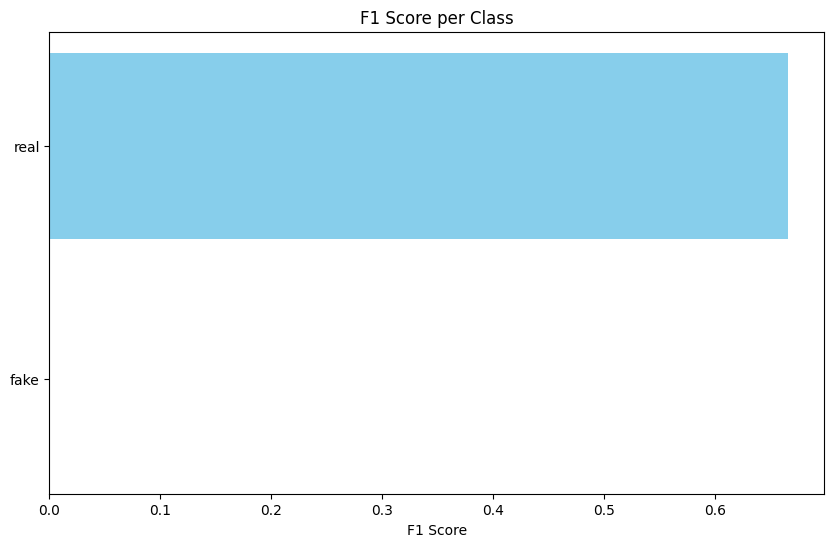

In [19]:
# Plot the F1 scores for each class
f1_scores = df_report['f1-score'][:-3]  # Exclude the 'average' row
classes = df_report.index[:-3]  # Exclude the 'average' row

plt.figure(figsize=(10, 6))
plt.barh(classes, f1_scores, color='skyblue')
plt.xlabel('F1 Score')
plt.title('F1 Score per Class')
plt.show()